# Выручка и качество данных
## Краткий результат
Проект использует учебные данные о продажах интернет-магазина. В 2013 сумма продаж составила **16 349 836** против **5 842 231** в 2012. Рост числа покупателей и частоты перекрывает падение среднего чека. Разложение показывает, как связаны показатели. Причины изменения поведения покупателей требуют отдельного исследования.

После восстановления дат внутри заказов: **27 657 заказов, 18 482 клиента, 29 356 216 суммы продаж**. Три строки на 34 исключены. Полный аудит: `docs/audit.md`.

## Контекст и методы
Цель анализа состоит в том, чтобы выбрать сегмент для повторных продаж и подготовить проверку предложения. PostgreSQL рассчитывает витрины; Python здесь читает результаты и рисует графики. Перед запуском выполни `scripts/run_pipeline.py` с настройками подключения из README.

### Основные допущения
Последняя покупка в данных датирована 2014-01-28. Полнота выгрузки требует отдельной проверки. Валюта, возвраты и скидки неизвестны. Когорты строятся по первой покупке в доступной истории. Для расчёта фактической маржи нужно уточнить смысл поля `cost` и состав расходов.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import psycopg2
from decimal import Decimal
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
conn = psycopg2.connect(os.environ.get('DATABASE_URL', ''))
def query(sql):
    with conn.cursor() as cur:
        cur.execute(sql)
        df = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
        for col in df.columns:
            if any(isinstance(v, Decimal) for v in df[col]):
                df[col] = df[col].map(lambda v: float(v) if v is not None else np.nan)
        return df
plt.rcParams.update({'figure.figsize': (10, 4.2), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GOLD = '#245b78', '#c88a28'
pd.options.display.float_format = '{:,.3f}'.format
query('SELECT * FROM portfolio.settings')

,observation_start,as_of_date
0,2010-12-29,2014-01-29


## Данные: единая политика очистки

In [2]:
query('SELECT * FROM portfolio.quality_summary ORDER BY metric')

,metric,value
0,clean_revenue,"29,356,216.000"
1,future_customer_creation,"18,484.000"
2,legacy_dec_2011_extra_lines,219.000
3,legacy_dec_2011_extra_revenue,"661,743.000"
4,negative_gross_profit_proxy_lines,0.000
5,null_birthdates,17.000
6,original_missing_date_lines,19.000
7,original_missing_date_revenue,"4,992.000"
8,quarantine_lines,3.000
9,quarantine_revenue,34.000


16 дат восстанавливаются только по другим строкам того же заказа. Остальные 3 строки остаются в quarantine. Исходные файлы сохранены без изменений. Строка продаж определяется сочетанием заказа и товара. Сначала считаем показатели заказа, затем клиента и месяца.

In [3]:
query('SELECT reason,count(*) AS lines,sum(sales_amount) AS excluded FROM portfolio.quarantine GROUP BY reason')

,reason,lines,excluded
0,missing_order_date,3,34.000


## Результаты: сопоставимые периоды

In [4]:
period = query('SELECT * FROM portfolio.period_metrics ORDER BY start_date,end_date')
period

,label,start_date,end_date,buyers,orders,revenue,frequency,aov
0,2011,2011-01-01,2012-01-01,2216,2216,"7,075,088.000",1.000,"3,192.729"
1,2012,2012-01-01,2013-01-01,3255,3269,"5,842,231.000",1.004,"1,787.162"
2,Jan 1-28 2013,2013-01-01,2013-01-29,487,489,"781,891.000",1.004,"1,598.959"
3,2013,2013-01-01,2014-01-01,17427,21287,"16,349,836.000",1.221,768.067
4,Jan 1-28 2014,2014-01-01,2014-01-29,834,871,"45,642.000",1.044,52.402


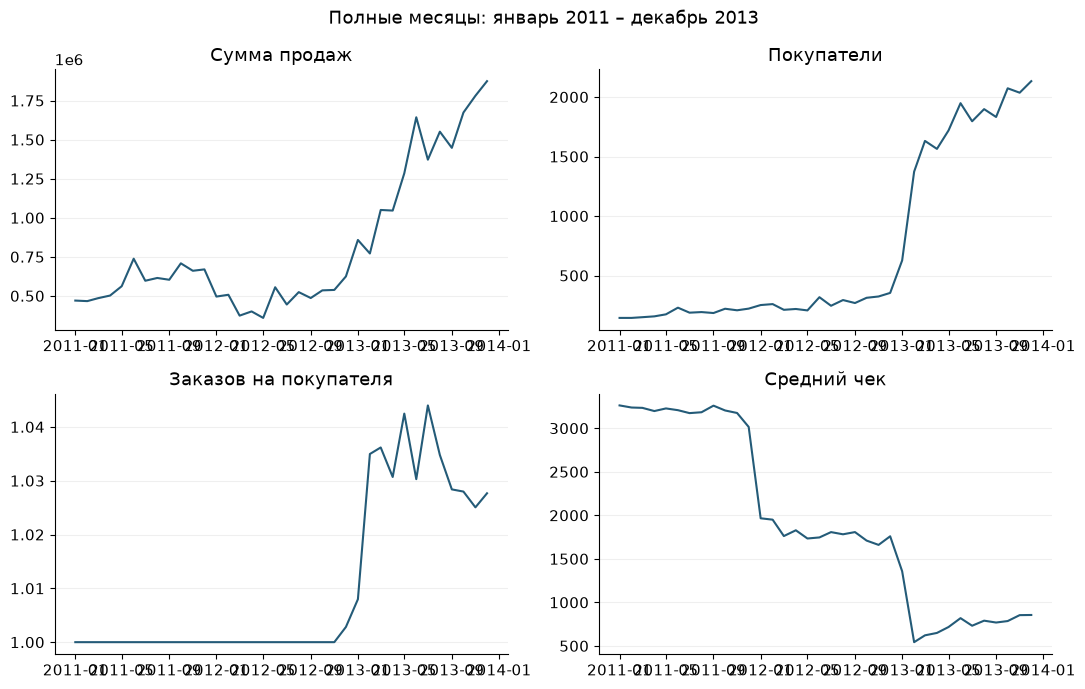

In [5]:
monthly = query('SELECT * FROM portfolio.monthly WHERE full_month ORDER BY month')
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, key, label in zip(axes.flat, ['revenue','buyers','frequency','aov'], ['Сумма продаж','Покупатели','Заказов на покупателя','Средний чек']):
    ax.plot(pd.to_datetime(monthly.month), monthly[key].astype(float), color=BLUE)
    ax.set_title(label); ax.grid(axis='y', alpha=.2)
fig.suptitle('Полные месяцы: январь 2011 – декабрь 2013'); fig.tight_layout(); plt.show()

Нельзя суммировать месячных уникальных покупателей для годового числа: один человек появляется в нескольких месяцах. Годовые B, F и A рассчитаны заново на уровне заказов.

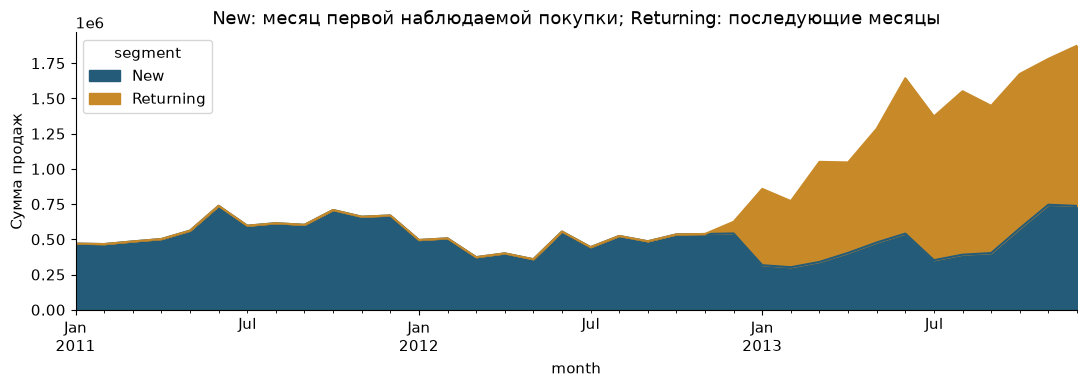

In [6]:
segments = query("SELECT * FROM portfolio.monthly_segments WHERE month >= DATE '2011-01-01' AND month < DATE '2014-01-01' ORDER BY month,segment")
p = segments.pivot(index='month',columns='segment',values='revenue').fillna(0).astype(float)
p.index = pd.to_datetime(p.index)
p.plot.area(color=[BLUE,GOLD], figsize=(11,4));plt.ylabel('Сумма продаж');plt.title('New: месяц первой наблюдаемой покупки; Returning: последующие месяцы');plt.tight_layout();plt.show()

### Точное разложение изменения выручки
В формуле `R = B × F × A` число покупателей обозначено B, количество заказов на покупателя `F = O/B`, средний чек `A = R/O`.

Порядок замены фиксирован: **B → F → A**:

`ΔB = (B₁ − B₀) × F₀ × A₀`,
`ΔF = B₁ × (F₁ − F₀) × A₀`,
`ΔA = B₁ × F₁ × (A₁ − A₀)`.

Сумма равна `R₁ − R₀`. Взаимодействия распределяются выбранным порядком; при другом порядке вклады будут другими. Разложение описывает арифметическую связь показателей. Для оценки причинного влияния потребовался бы отдельный дизайн исследования.

In [7]:
bridge = query('SELECT * FROM portfolio.revenue_bridge ORDER BY comparison')
bridge

,comparison,revenue_before,revenue_after,buyers_effect,frequency_effect,aov_effect,total_change
0,2012 -> 2013,"5,842,231.000","16,349,836.000","25,436,589.165","6,764,487.053","-21,693,471.218","10,507,605.000"
1,Jan 1-28: 2013 -> 2014,"781,891.000","45,642.000","557,117.407","53,684.970","-1,347,051.376","-736,249.000"


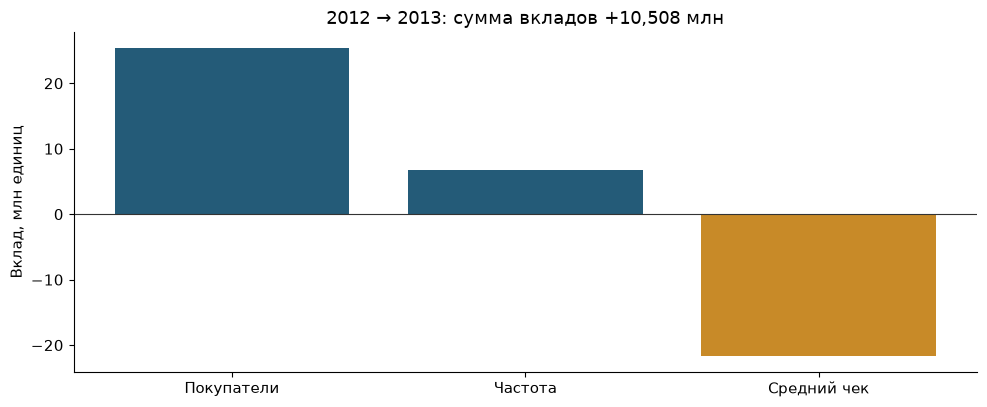

In [8]:
b=bridge.iloc[0]
values=[float(b.buyers_effect),float(b.frequency_effect),float(b.aov_effect)]
assert abs(sum(values)-float(b.total_change)) < 1e-6
plt.bar(['Покупатели','Частота','Средний чек'],np.array(values)/1e6,color=[BLUE,BLUE,GOLD]);plt.axhline(0,color='#333',lw=.8)
plt.ylabel('Вклад, млн единиц');plt.title('2012 → 2013: сумма вкладов +10,508 млн');plt.tight_layout();plt.show()

### Почему январь нельзя объяснять только удержанием
Сравнение 1–28 января с 1–28 января показывает падение **781 891 → 45 642**. В 2014 в этом окне отсутствуют велосипеды. Чтобы объяснить это падение, сначала нужно проверить ассортимент и полноту выгрузки.

In [9]:
query('SELECT * FROM portfolio.january_category ORDER BY category,year')

,year,category,orders,revenue
0,2013,Accessories,374,"14,112.000"
1,2014,Accessories,774,"30,332.000"
2,2013,Bikes,454,"761,272.000"
3,2013,Clothing,146,"6,507.000"
4,2014,Clothing,316,"15,310.000"


## Независимая проверка

In [10]:
import sys
sys.path.insert(0,str(ROOT/'scripts'))
from verify import verify
verify(conn)

{'independent_comparisons': 20122,
 'raw_rows': 60398,
 'raw_orders': 27659,
 'clean_orders': 27657,
 'clean_customers': 18482,
 'date_recovered_lines': 16,
 'excluded_lines': 3,
 'excluded_revenue': '34',
 'clean_revenue': '29356216',
 'repeat_customers': 6865,
 'same_day_second': 8,
 'observation_start': datetime.date(2010, 12, 29),
 'observation_end': datetime.date(2014, 1, 28),
 'sql_checks': 'passed',
 'python_checks': 'passed'}

## Вывод
По этим данным можно изучить покупки и сравнить возврат клиентов за одинаковый срок. Для расчёта фактической прибыли нужны сведения о затратах, скидках и возвратах. Во втором ноутбуке выберем сегмент для предложения и рассчитаем условия его окупаемости.

In [11]:
conn.close()